# Pothole-440: Comparing Four Depth Models

This notebook compares four trained models on the **same 64 held-out test images**:

1. MiDaS 3.1
2. Depth Anything V1 Small
3. Depth Anything V2 Small
4. YOLO26-Depth Nano

It creates the tables and figures needed for the Results section of the report:
- MAE and RMSE (how close predictions are to the prepared target)
- Model size, number of parameters and approximate prediction time
- Side-by-side prediction maps for selected test images
- CSV files and a ZIP of the results

**Important:** The target is a normalized scanner-grayscale value. It is not measured depth in metres or centimetres. The results show how closely each model matches this prepared target.


## 0. Before running

In Kaggle, attach these two datasets using **Add Input**:

- The dataset containing the four trained model checkpoints
- The dataset containing `Pothole440_Grouped`, `Pothole440_Targets_Global` and `Pothole440_Targets_Corrected`

The notebook finds the corrected manifest automatically. It uses the `split` column in that manifest to select the test images.


In [1]:
# Install missing packages without forcing upgrades to the whole environment.
# If the imports in the next cell already work, you may skip this cell.
!pip -q install transformers ultralytics


In [2]:
import os, gc, time, json, math, warnings, shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
from ultralytics import YOLO

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("Transformers:", __import__('transformers').__version__)
print("Ultralytics:", __import__('ultralytics').__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

# Folder containing your four trained checkpoints.
MODEL_ROOT = Path(
    "/kaggle/input/datasets/siddharthk7704/pothole440-model-checkpoints/"
    "Pothole440 Model Comparison"
)

# The preparation dataset is a separate Kaggle input. The manifest is found automatically below.
PREP_DIR = Path("/kaggle/input/datasets/siddharthk7704/pothole-dataset")

TARGET_SIZE = 256
YOLO_IMGSZ = 640
OUTPUT_ROOT = Path("/kaggle/working/Pothole440_Model_Comparison")
PRED_ROOT = OUTPUT_ROOT / "05_Evaluation" / "predictions"
VIS_ROOT = OUTPUT_ROOT / "05_Evaluation" / "visualizations"
METRIC_ROOT = OUTPUT_ROOT / "05_Evaluation" / "metrics"
REPORT_ROOT = OUTPUT_ROOT / "06_Reports"

for p in [PRED_ROOT, VIS_ROOT, METRIC_ROOT, REPORT_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

print("Checkpoint root exists:", MODEL_ROOT.is_dir())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cuda:0
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Ultralytics: 8.4.216
GPU: Tesla T4
GPU memory (GB): 14.56
Checkpoint root exists: True


In [3]:
# Find the corrected manifest. This makes the notebook tolerant of a different Kaggle slug.
manifest_candidates = list(Path("/kaggle/input").rglob("training_manifest_corrected.csv"))
if not manifest_candidates:
    raise FileNotFoundError(
        "Could not find training_manifest_corrected.csv. "
        "Attach the preparation dataset containing Pothole440_Targets_Corrected."
    )

# Prefer the manifest beneath a folder named Pothole440_Targets_Corrected.
preferred = [p for p in manifest_candidates if p.parent.name == "Pothole440_Targets_Corrected"]
MANIFEST_PATH = preferred[0] if preferred else manifest_candidates[0]
PREP_DIR = MANIFEST_PATH.parent.parent

GROUPED_ROOT = PREP_DIR / "Pothole440_Grouped"
GLOBAL_ROOT = PREP_DIR / "Pothole440_Targets_Global"
CORRECTED_ROOT = PREP_DIR / "Pothole440_Targets_Corrected"

print("Preparation root:", PREP_DIR)
print("Manifest:", MANIFEST_PATH)
print("Grouped RGB root exists:", GROUPED_ROOT.is_dir())
print("Global targets root exists:", GLOBAL_ROOT.is_dir())
print("Corrected masks root exists:", CORRECTED_ROOT.is_dir())

assert MODEL_ROOT.is_dir(), f"Checkpoint folder not found: {MODEL_ROOT}"
assert GROUPED_ROOT.is_dir(), f"Missing: {GROUPED_ROOT}"
assert GLOBAL_ROOT.is_dir(), f"Missing: {GLOBAL_ROOT}"
assert CORRECTED_ROOT.is_dir(), f"Missing: {CORRECTED_ROOT}"

Preparation root: /kaggle/input/datasets/siddharthk7704/pothole-dataset
Manifest: /kaggle/input/datasets/siddharthk7704/pothole-dataset/Pothole440_Targets_Corrected/training_manifest_corrected.csv
Grouped RGB root exists: True
Global targets root exists: True
Corrected masks root exists: True


## 1. Find the test images and check the files

The corrected manifest is the source of truth. We select rows whose `split` value is `test`; we do not use filename prefixes.

The prepared test split should contain **64 images**. The notebook stops if files are missing or the count is different, so an incorrect dataset is not evaluated by accident.


In [4]:
df = pd.read_csv(MANIFEST_PATH)
print("Manifest rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head(3))

def first_existing_column(frame, choices, label):
    for c in choices:
        if c in frame.columns:
            return c
    raise KeyError(f"Cannot find {label}. Tried {choices}; found {frame.columns.tolist()}")

SPLIT_COL = first_existing_column(df, ["split"], "split column")
NAME_COL = first_existing_column(df, ["filename", "file_name"], "filename column")
RGB_COL = first_existing_column(df, ["rgb_path", "image_path", "image"], "RGB path")
TARGET_COL = first_existing_column(df, ["target_path", "depth_target_path"], "target path")
VALID_COL = first_existing_column(
    df,
    ["corrected_valid_path", "valid_path", "valid_mask_path"],
    "corrected validity-mask path"
)

def resolve_manifest_path(value, kind):
    if pd.isna(value):
        return None
    raw = str(value)
    p = Path(raw)
    if p.is_file():
        return p

    # Original manifest paths were created under /kaggle/working/.
    marker = "/kaggle/working/"
    if raw.startswith(marker):
        candidate = PREP_DIR / raw[len(marker):]
        if candidate.is_file():
            return candidate

    # Search only the expected source folder for the matching basename.
    roots = {
        "rgb": [GROUPED_ROOT],
        "target": [GLOBAL_ROOT],
        "valid": [CORRECTED_ROOT, CORRECTED_ROOT / "valid_masks"]
    }[kind]

    for root in roots:
        if root.exists():
            matches = list(root.rglob(p.name))
            if matches:
                return matches[0]
    return p

df["rgb_resolved"] = df[RGB_COL].apply(lambda x: resolve_manifest_path(x, "rgb"))
df["target_resolved"] = df[TARGET_COL].apply(lambda x: resolve_manifest_path(x, "target"))
df["valid_resolved"] = df[VALID_COL].apply(lambda x: resolve_manifest_path(x, "valid"))

def path_ok(x):
    return x is not None and Path(x).is_file()

missing = {
    "rgb": int((~df["rgb_resolved"].apply(path_ok)).sum()),
    "target": int((~df["target_resolved"].apply(path_ok)).sum()),
    "valid_mask": int((~df["valid_resolved"].apply(path_ok)).sum())
}
print("Missing files:", missing)
print("Validity-mask column selected:", VALID_COL)
print("Manifest split counts:")
display(df[SPLIT_COL].value_counts().rename_axis("split").to_frame("images"))

assert sum(missing.values()) == 0, (
    "Some manifest paths could not be resolved. Inspect the paths above and correct PREP_DIR."
)

test_df = df[df[SPLIT_COL].astype(str).str.lower().eq("test")].copy()
test_df = test_df.sort_values(NAME_COL).reset_index(drop=True)

print("Test images:", len(test_df))
assert len(test_df) == 64, (
    f"Expected 64 prepared test images based on the preparation audit, found {len(test_df)}. "
    "Do not silently proceed until the manifest/input is checked."
)
assert test_df[NAME_COL].is_unique, "Duplicate test filenames found."

Manifest rows: 435
Columns: ['split', 'filename', 'rgb_path', 'mask_path', 'target_path', 'valid_path', 'height', 'width', 'valid_pixels', 'valid_fraction', 'corrected_valid_path']


,split,filename,rgb_path,mask_path,target_path,valid_path,height,width,valid_pixels,valid_fraction,corrected_valid_path
0,train,test__2022_05_22_pothole_10_horizantal_aug1.png,/kaggle/working/Pothole440_Grouped/train/rgb/t...,/kaggle/working/Pothole440_Grouped/train/mask/...,/kaggle/working/Pothole440_Targets_Global/trai...,/kaggle/working/Pothole440_Targets_Global/trai...,800,1200,113419,0.118145,/kaggle/working/Pothole440_Targets_Global/trai...
1,train,test__2022_05_22_pothole_11_horizantal_vertica...,/kaggle/working/Pothole440_Grouped/train/rgb/t...,/kaggle/working/Pothole440_Grouped/train/mask/...,/kaggle/working/Pothole440_Targets_Global/trai...,/kaggle/working/Pothole440_Targets_Global/trai...,800,1200,115216,0.120017,/kaggle/working/Pothole440_Targets_Global/trai...
2,train,test__2022_05_22_pothole_11_horizantal_vertica...,/kaggle/working/Pothole440_Grouped/train/rgb/t...,/kaggle/working/Pothole440_Grouped/train/mask/...,/kaggle/working/Pothole440_Targets_Global/trai...,/kaggle/working/Pothole440_Targets_Global/trai...,800,1200,115376,0.120183,/kaggle/working/Pothole440_Targets_Global/trai...


Missing files: {'rgb': 0, 'target': 0, 'valid_mask': 0}
Validity-mask column selected: corrected_valid_path
Manifest split counts:


,images
split,
train,305
val,66
test,64


Test images: 64


## 2. Load the reference images and targets

Each reference target and validity mask is resized to 256 × 256.

- The target uses smooth resizing.
- The validity mask uses nearest-neighbour resizing so it stays a clean black-and-white mask.
- Pixels outside the validity mask are not included in the error scores.

The same target and mask are used for all four models.


In [5]:
def load_reference(row):
    rgb = Image.open(row["rgb_resolved"]).convert("RGB")
    target = np.load(row["target_resolved"]).astype(np.float32)

    valid_img = cv2.imread(str(row["valid_resolved"]), cv2.IMREAD_GRAYSCALE)
    if valid_img is None:
        raise RuntimeError(f"Cannot read validity mask: {row['valid_resolved']}")

    if target.shape != valid_img.shape:
        raise ValueError(
            f"Target/mask shape mismatch for {row[NAME_COL]}: "
            f"{target.shape} vs {valid_img.shape}"
        )

    target = cv2.resize(
        target, (TARGET_SIZE, TARGET_SIZE), interpolation=cv2.INTER_LINEAR
    )
    valid = cv2.resize(
        (valid_img > 127).astype(np.uint8),
        (TARGET_SIZE, TARGET_SIZE),
        interpolation=cv2.INTER_NEAREST
    ).astype(bool)

    target = np.nan_to_num(target, nan=0.0, posinf=0.0, neginf=0.0)
    target = np.clip(target, 0.0, 1.0)

    if valid.sum() == 0:
        raise ValueError(f"Empty corrected validity mask for {row[NAME_COL]}")

    return rgb, target, valid

# Load and check every test reference before running the models.
reference_cache = {}
for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Checking test references"):
    reference_cache[str(row[NAME_COL])] = load_reference(row)

valid_counts = [int(v[2].sum()) for v in reference_cache.values()]
print("Reference images loaded:", len(reference_cache))
print("Valid pixels per image — min/median/max:",
      min(valid_counts), int(np.median(valid_counts)), max(valid_counts))

Checking test references:   0%|          | 0/64 [00:00<?, ?it/s]

Reference images loaded: 64
Valid pixels per image — min/median/max: 6381 15775 62383


## 3. Find the four trained checkpoints

The notebook looks for the best checkpoint in each model folder and reports its file size.


In [6]:
MODEL_DIRS = {
    "MiDaS 3.1": MODEL_ROOT / "01_MiDaS31",
    "Depth Anything V1": MODEL_ROOT / "02_DepthAnythingV1",
    "Depth Anything V2": MODEL_ROOT / "03_DepthAnythingV2",
    "YOLO26-Depth": MODEL_ROOT / "04_YOLO26_Depth",
}

def find_checkpoint(folder, suffix):
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing model folder: {folder}")

    # Prefer the known best-checkpoint filename.
    preferred_names = ["best_checkpoint.pth", "best.pt"]
    for name in preferred_names:
        preferred = list(folder.rglob(name))
        if preferred:
            return preferred[0]

    matches = sorted(folder.rglob(f"*{suffix}"))
    if not matches:
        raise FileNotFoundError(f"No {suffix} checkpoint found under {folder}")
    if len(matches) > 1:
        print(f"Multiple {suffix} files under {folder}; using:", matches[0])
    return matches[0]

CHECKPOINTS = {
    "MiDaS 3.1": find_checkpoint(MODEL_DIRS["MiDaS 3.1"], ".pth"),
    "Depth Anything V1": find_checkpoint(MODEL_DIRS["Depth Anything V1"], ".pth"),
    "Depth Anything V2": find_checkpoint(MODEL_DIRS["Depth Anything V2"], ".pth"),
    "YOLO26-Depth": find_checkpoint(MODEL_DIRS["YOLO26-Depth"], ".pt"),
}

checkpoint_inventory = []
for name, path in CHECKPOINTS.items():
    size_mb = path.stat().st_size / (1024 ** 2)
    checkpoint_inventory.append({
        "model": name,
        "checkpoint": str(path),
        "checkpoint_size_MB": size_mb
    })
display(pd.DataFrame(checkpoint_inventory))

,model,checkpoint,checkpoint_size_MB
0,MiDaS 3.1,/kaggle/input/datasets/siddharthk7704/pothole4...,156.265393
1,Depth Anything V1,/kaggle/input/datasets/siddharthk7704/pothole4...,94.658071
2,Depth Anything V2,/kaggle/input/datasets/siddharthk7704/pothole4...,94.658071
3,YOLO26-Depth,/kaggle/input/datasets/siddharthk7704/pothole4...,10.108360


## 4. How the models are compared

All models are scored against the same valid pixels in the same test images.

- **MAE:** average absolute difference between prediction and target. Lower is better.
- **RMSE:** similar to MAE, but gives larger errors more weight. Lower is better.
- **Image mean/median:** summarize the error image by image.
- **Prediction time:** approximate time per image after a warm-up run.
- **Parameters and checkpoint size:** give an idea of model size.

MiDaS and both Depth Anything models use the calibration values saved with their trained checkpoints. YOLO26-Depth is compared directly with the prepared target.

No model is adjusted using the test images. Timing is approximate because the models use different input processing and image sizes.


In [7]:
class LinearCalibration(nn.Module):
    def __init__(self):
        super().__init__()
        self.scale = nn.Parameter(torch.tensor(1.0))
        self.bias = nn.Parameter(torch.tensor(0.0))

    def forward(self, x):
        return self.scale * x + self.bias

def resize_prediction(pred, size=TARGET_SIZE):
    pred = np.asarray(pred, dtype=np.float32).squeeze()
    if pred.ndim != 2:
        raise ValueError(f"Expected 2D depth prediction after squeeze, got {pred.shape}")
    if pred.shape != (size, size):
        pred = cv2.resize(pred, (size, size), interpolation=cv2.INTER_LINEAR)
    if not np.isfinite(pred).all():
        raise ValueError("Prediction contains NaN or Inf values.")
    
    return pred.astype(np.float32)

def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def save_prediction(model_key, filename, pred):
    out_dir = PRED_ROOT / model_key.replace(" ", "_").replace("-", "_")
    out_dir.mkdir(parents=True, exist_ok=True)
    np.save(out_dir / f"{Path(filename).stem}.npy", pred.astype(np.float32))
    preview = (np.clip(pred, 0, 1) * 255).round().astype(np.uint8)
    Image.fromarray(preview).save(out_dir / f"{Path(filename).stem}.png")

def evaluate_prediction(filename, pred, target, valid):
    pred = np.asarray(pred, dtype=np.float32)
    err = pred[valid] - target[valid]
    return {
        "filename": filename,
        "valid_pixels": int(valid.sum()),
        "MAE": float(np.mean(np.abs(err))),
        "RMSE": float(np.sqrt(np.mean(err ** 2))),
        "prediction_min_valid": float(np.min(pred[valid])),
        "prediction_max_valid": float(np.max(pred[valid])),
        "prediction_mean_valid": float(np.mean(pred[valid])),
    }

def summarize_model(model_name, rows, total_time, parameter_count, checkpoint_path, input_size):
    frame = pd.DataFrame(rows)
    n_valid = int(frame["valid_pixels"].sum())
    # Recompute pooled errors from saved per-image metrics, weighting by valid pixel counts.
    pixel_mae = float(np.average(frame["MAE"], weights=frame["valid_pixels"]))
    pixel_rmse = float(np.sqrt(np.average(frame["RMSE"] ** 2, weights=frame["valid_pixels"])))
    return {
        "model": model_name,
        "test_images": int(len(frame)),
        "valid_pixels": n_valid,
        "pixel_weighted_MAE": pixel_mae,
        "pixel_weighted_RMSE": pixel_rmse,
        "image_mean_MAE": float(frame["MAE"].mean()),
        "image_mean_RMSE": float(frame["RMSE"].mean()),
        "image_median_MAE": float(frame["MAE"].median()),
        "image_median_RMSE": float(frame["RMSE"].median()),
        "mean_inference_ms_per_image": float(frame["inference_ms"].mean()),
        "median_inference_ms_per_image": float(frame["inference_ms"].median()),
        "p90_inference_ms_per_image": float(
            frame["inference_ms"].quantile(0.90)
        ),
        "parameters_M": (float(parameter_count) / 1e6) if parameter_count is not None else np.nan,
        "checkpoint_size_MB": checkpoint_path.stat().st_size / (1024 ** 2),
        "inference_input_size": input_size,
    }

## 5. Evaluate MiDaS 3.1

Load the trained MiDaS checkpoint, predict the test images and compare the predictions with the reference targets.


In [8]:
HF_CONFIGS = {
    "MiDaS 3.1": "Intel/dpt-swinv2-tiny-256",
    "Depth Anything V1": "LiheYoung/depth-anything-small-hf",
    "Depth Anything V2": "depth-anything/Depth-Anything-V2-Small-hf",
}

def load_hf_depth_model(model_name, model_id):
    processor = AutoImageProcessor.from_pretrained(model_id)
    model = AutoModelForDepthEstimation.from_pretrained(model_id)
    ckpt = torch.load(CHECKPOINTS[model_name], map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"], strict=True)

    calibration = LinearCalibration()
    calibration.load_state_dict(ckpt["calibration_state_dict"], strict=True)

    model.to(DEVICE).eval()
    calibration.to(DEVICE).eval()
    return processor, model, calibration, ckpt

def hf_predict_one(rgb_image, processor, model, calibration):
    inputs = processor(images=rgb_image, return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(DEVICE)

    with torch.inference_mode():
        raw = model(pixel_values=pixel_values).predicted_depth
        if raw.ndim == 3:
            raw = raw.unsqueeze(1)
        raw = F.interpolate(
            raw,
            size=(TARGET_SIZE, TARGET_SIZE),
            mode="bilinear",
            align_corners=False
        ).squeeze(1)
        pred = calibration(raw.float())[0]

    return pred.detach().cpu().numpy().astype(np.float32)

def run_hf_evaluation(model_name, model_id):
    processor, model, calibration, ckpt = load_hf_depth_model(model_name, model_id)
    params = sum(p.numel() for p in model.parameters())
    # ------------------------------------------------
    # Warm-up: 5 iterations, excluded from measurement
    # ------------------------------------------------
    
    first_rgb = reference_cache[str(test_df.iloc[0][NAME_COL])][0]
    
    for _ in range(5):
        _ = resize_prediction(
            hf_predict_one(first_rgb, processor, model, calibration)
        )
    
    sync_device()
    
    records = []
    total_seconds = 0.0
    
    model_key = model_name.replace(" ", "_").replace("-", "_")
    
    for _, row in tqdm(
        test_df.iterrows(),
        total=len(test_df),
        desc=f"Testing {model_name}"
    ):
    
        filename = str(row[NAME_COL])
        rgb, target, valid = reference_cache[filename]
    
        # Start timing
        sync_device()
        t0 = time.perf_counter()
    
        # Complete inference pipeline
        pred = hf_predict_one(
            rgb, processor, model, calibration
        )
    
        pred = resize_prediction(pred)
    
        # End timing
        sync_device()
        elapsed = time.perf_counter() - t0
    
        total_seconds += elapsed
    
        # Metrics and file saving excluded from timing
        metrics = evaluate_prediction(
            filename, pred, target, valid
        )
    
        metrics["inference_ms"] = elapsed * 1000
    
        records.append(metrics)
    
        save_prediction(model_key, filename, pred)


    summary = summarize_model(
        model_name, records, total_seconds, params, CHECKPOINTS[model_name], "processor native"
    )
    # Record the saved calibration values so their effect can be described in the report.
    summary["calibration_scale"] = float(calibration.scale.item())
    summary["calibration_bias"] = float(calibration.bias.item())
    per_image = pd.DataFrame(records)
    per_image.to_csv(METRIC_ROOT / f"{model_key}_per_image.csv", index=False)

    print("Checkpoint epoch:", ckpt.get("epoch", "not stored"))
    print("Checkpoint validation loss:", ckpt.get("val_loss", "not stored"))
    print("Calibration scale/bias:", calibration.scale.item(), calibration.bias.item())

    del model, calibration, processor
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return summary, per_image

all_summaries = []
all_per_image = {}

midas_summary, midas_per_image = run_hf_evaluation("MiDaS 3.1", HF_CONFIGS["MiDaS 3.1"])
all_summaries.append(midas_summary)
all_per_image["MiDaS 3.1"] = midas_per_image
display(pd.DataFrame([midas_summary]))

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.72k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  164MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Testing MiDaS 3.1:   0%|          | 0/64 [00:00<?, ?it/s]

Checkpoint epoch: 5
Checkpoint validation loss: 0.0073135414215022045
Calibration scale/bias: 0.0038431722205132246 0.09252336621284485


,model,test_images,valid_pixels,pixel_weighted_MAE,pixel_weighted_RMSE,image_mean_MAE,image_mean_RMSE,image_median_MAE,image_median_RMSE,mean_inference_ms_per_image,median_inference_ms_per_image,p90_inference_ms_per_image,parameters_M,checkpoint_size_MB,inference_input_size,calibration_scale,calibration_bias
0,MiDaS 3.1,64,1183198,0.118095,0.155661,0.124404,0.155518,0.115607,0.147527,42.842339,42.341883,43.894963,40.930795,156.265393,processor native,0.003843,0.092523


## 6. Evaluate Depth Anything V1 and V2

Evaluate both models in the same way. Their saved calibration values are used exactly as stored in the checkpoints.


In [9]:
da1_summary, da1_per_image = run_hf_evaluation(
    "Depth Anything V1", HF_CONFIGS["Depth Anything V1"]
)
all_summaries.append(da1_summary)
all_per_image["Depth Anything V1"] = da1_per_image
display(pd.DataFrame([da1_summary]))

preprocessor_config.json:   0%|          | 0.00/437 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/954 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Testing Depth Anything V1:   0%|          | 0/64 [00:00<?, ?it/s]

Checkpoint epoch: 4
Checkpoint validation loss: 0.00681416150605814
Calibration scale/bias: 0.018893616273999214 0.5604336857795715


,model,test_images,valid_pixels,pixel_weighted_MAE,pixel_weighted_RMSE,image_mean_MAE,image_mean_RMSE,image_median_MAE,image_median_RMSE,mean_inference_ms_per_image,median_inference_ms_per_image,p90_inference_ms_per_image,parameters_M,checkpoint_size_MB,inference_input_size,calibration_scale,calibration_bias
0,Depth Anything V1,64,1183198,0.098261,0.141261,0.107272,0.143837,0.098741,0.141069,86.612458,86.618752,87.799719,24.785089,94.658071,processor native,0.018894,0.560434


In [10]:
da2_summary, da2_per_image = run_hf_evaluation(
    "Depth Anything V2", HF_CONFIGS["Depth Anything V2"]
)
all_summaries.append(da2_summary)
all_per_image["Depth Anything V2"] = da2_per_image
display(pd.DataFrame([da2_summary]))

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Testing Depth Anything V2:   0%|          | 0/64 [00:00<?, ?it/s]

Checkpoint epoch: 4
Checkpoint validation loss: 0.008439362151407157
Calibration scale/bias: -0.01824030838906765 0.8157784342765808


,model,test_images,valid_pixels,pixel_weighted_MAE,pixel_weighted_RMSE,image_mean_MAE,image_mean_RMSE,image_median_MAE,image_median_RMSE,mean_inference_ms_per_image,median_inference_ms_per_image,p90_inference_ms_per_image,parameters_M,checkpoint_size_MB,inference_input_size,calibration_scale,calibration_bias
0,Depth Anything V2,64,1183198,0.100625,0.143227,0.110825,0.147625,0.111513,0.15999,87.15471,87.242758,88.225223,24.785089,94.658071,processor native,-0.01824,0.815778


## 7. Evaluate YOLO26-Depth

YOLO26-Depth predicts at 640 × 640. Its output is resized to the same 256 × 256 grid used for the reference targets.

Its predictions are compared directly with the target; no new calibration is fitted on the test images.


In [11]:
yolo_model = YOLO(str(CHECKPOINTS["YOLO26-Depth"]))
if getattr(yolo_model, "task", None) != "depth":
    warnings.warn(f"YOLO checkpoint task is {getattr(yolo_model, 'task', None)!r}; expected 'depth'.")

yolo_params = sum(p.numel() for p in yolo_model.model.parameters())
yolo_device = 0 if DEVICE.type == "cuda" else "cpu"

# ------------------------------------------------
# Warm-up: 5 iterations, excluded from measurement
# ------------------------------------------------

first_rgb = reference_cache[
    str(test_df.iloc[0][NAME_COL])
][0]

for _ in range(5):

    warm_result = yolo_model.predict(
        source=first_rgb,
        imgsz=YOLO_IMGSZ,
        device=yolo_device,
        verbose=False
    )[0]

    warm_depth = getattr(warm_result, "depth", None)

    if warm_depth is None:
        raise RuntimeError("YOLO26 returned no depth output.")

    _ = resize_prediction(
        warm_depth.data.detach().float().cpu().numpy()
    )

sync_device()

# ------------------------------------------------
# Evaluation
# ------------------------------------------------

yolo_records = []
yolo_total_seconds = 0.0
yolo_key = "YOLO26_Depth"

for _, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="Testing YOLO26-Depth"
):

    filename = str(row[NAME_COL])
    rgb, target, valid = reference_cache[filename]

    sync_device()
    t0 = time.perf_counter()

    # Inference using cached RGB image
    result = yolo_model.predict(
        source=rgb,
        imgsz=YOLO_IMGSZ,
        device=yolo_device,
        verbose=False
    )[0]

    depth_result = getattr(result, "depth", None)

    if depth_result is None:
        raise RuntimeError("YOLO26 returned no depth output.")

    # Include output transfer and resizing in timing
    pred_tensor = (
        depth_result.data.detach()
        .float()
        .cpu()
        .numpy()
    )

    pred = resize_prediction(pred_tensor)

    sync_device()
    elapsed = time.perf_counter() - t0

    yolo_total_seconds += elapsed

    # Evaluation and saving excluded from timing
    metrics = evaluate_prediction(
        filename, pred, target, valid
    )

    metrics["inference_ms"] = elapsed * 1000

    yolo_records.append(metrics)

    save_prediction(yolo_key, filename, pred)

yolo_per_image = pd.DataFrame(yolo_records)

yolo_per_image.to_csv(
    METRIC_ROOT / "YOLO26_Depth_per_image.csv",
    index=False
)

yolo_summary = summarize_model(
    "YOLO26-Depth",
    yolo_records,
    yolo_total_seconds,
    yolo_params,
    CHECKPOINTS["YOLO26-Depth"],
    f"{YOLO_IMGSZ}x{YOLO_IMGSZ}"
)

all_summaries.append(yolo_summary)
all_per_image["YOLO26-Depth"] = yolo_per_image

print("YOLO task:", getattr(yolo_model, "task", "unknown"))
display(pd.DataFrame([yolo_summary]))


del yolo_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Testing YOLO26-Depth:   0%|          | 0/64 [00:00<?, ?it/s]

YOLO task: depth


,model,test_images,valid_pixels,pixel_weighted_MAE,pixel_weighted_RMSE,image_mean_MAE,image_mean_RMSE,image_median_MAE,image_median_RMSE,mean_inference_ms_per_image,median_inference_ms_per_image,p90_inference_ms_per_image,parameters_M,checkpoint_size_MB,inference_input_size
0,YOLO26-Depth,64,1183198,0.11027,0.152509,0.121729,0.155358,0.125669,0.165201,22.010609,21.930357,23.113722,5.174945,10.10836,640x640


## 8. Save the comparison table

The table contains the main accuracy and model-size results for the report. The pixel-weighted scores give more weight to images with more valid pixels; the image-wise scores give each image equal weight.

The parameter count includes the model weights, not the two saved calibration values. Checkpoint size is the size of the saved file.


In [12]:
summary_df = pd.DataFrame(all_summaries)

# Keep the model order consistent throughout the report.
model_order = ["MiDaS 3.1", "Depth Anything V1", "Depth Anything V2", "YOLO26-Depth"]
summary_df["model"] = pd.Categorical(summary_df["model"], categories=model_order, ordered=True)
summary_df = summary_df.sort_values("model").reset_index(drop=True)
summary_df["model"] = summary_df["model"].astype(str)

summary_path = REPORT_ROOT / "model_comparison.csv"
summary_df.to_csv(summary_path, index=False)

combined_per_image = []
for model_name, frame in all_per_image.items():
    tmp = frame.copy()
    tmp.insert(0, "model", model_name)
    combined_per_image.append(tmp)
combined_per_image = pd.concat(combined_per_image, ignore_index=True)
combined_per_image.to_csv(METRIC_ROOT / "all_models_per_image_metrics.csv", index=False)

print("Saved:", summary_path)
print("Saved:", METRIC_ROOT / "all_models_per_image_metrics.csv")
display(summary_df)

Saved: /kaggle/working/Pothole440_Model_Comparison/06_Reports/model_comparison.csv
Saved: /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/metrics/all_models_per_image_metrics.csv


,model,test_images,valid_pixels,pixel_weighted_MAE,pixel_weighted_RMSE,image_mean_MAE,image_mean_RMSE,image_median_MAE,image_median_RMSE,mean_inference_ms_per_image,median_inference_ms_per_image,p90_inference_ms_per_image,parameters_M,checkpoint_size_MB,inference_input_size,calibration_scale,calibration_bias
0,MiDaS 3.1,64,1183198,0.118095,0.155661,0.124404,0.155518,0.115607,0.147527,42.842339,42.341883,43.894963,40.930795,156.265393,processor native,0.003843,0.092523
1,Depth Anything V1,64,1183198,0.098261,0.141261,0.107272,0.143837,0.098741,0.141069,86.612458,86.618752,87.799719,24.785089,94.658071,processor native,0.018894,0.560434
2,Depth Anything V2,64,1183198,0.100625,0.143227,0.110825,0.147625,0.111513,0.159990,87.154710,87.242758,88.225223,24.785089,94.658071,processor native,-0.018240,0.815778
3,YOLO26-Depth,64,1183198,0.110270,0.152509,0.121729,0.155358,0.125669,0.165201,22.010609,21.930357,23.113722,5.174945,10.108360,640x640,NaN,NaN


## 9. Make side-by-side prediction figures

The same colour scale (0 to 1) is used for the reference and every model. This is important: each prediction is **not** stretched separately to make it look better.

The figure includes the RGB image, reference target, validity mask and all four model predictions. The RGB image is resized to the same square display size so the panels can be compared side by side.


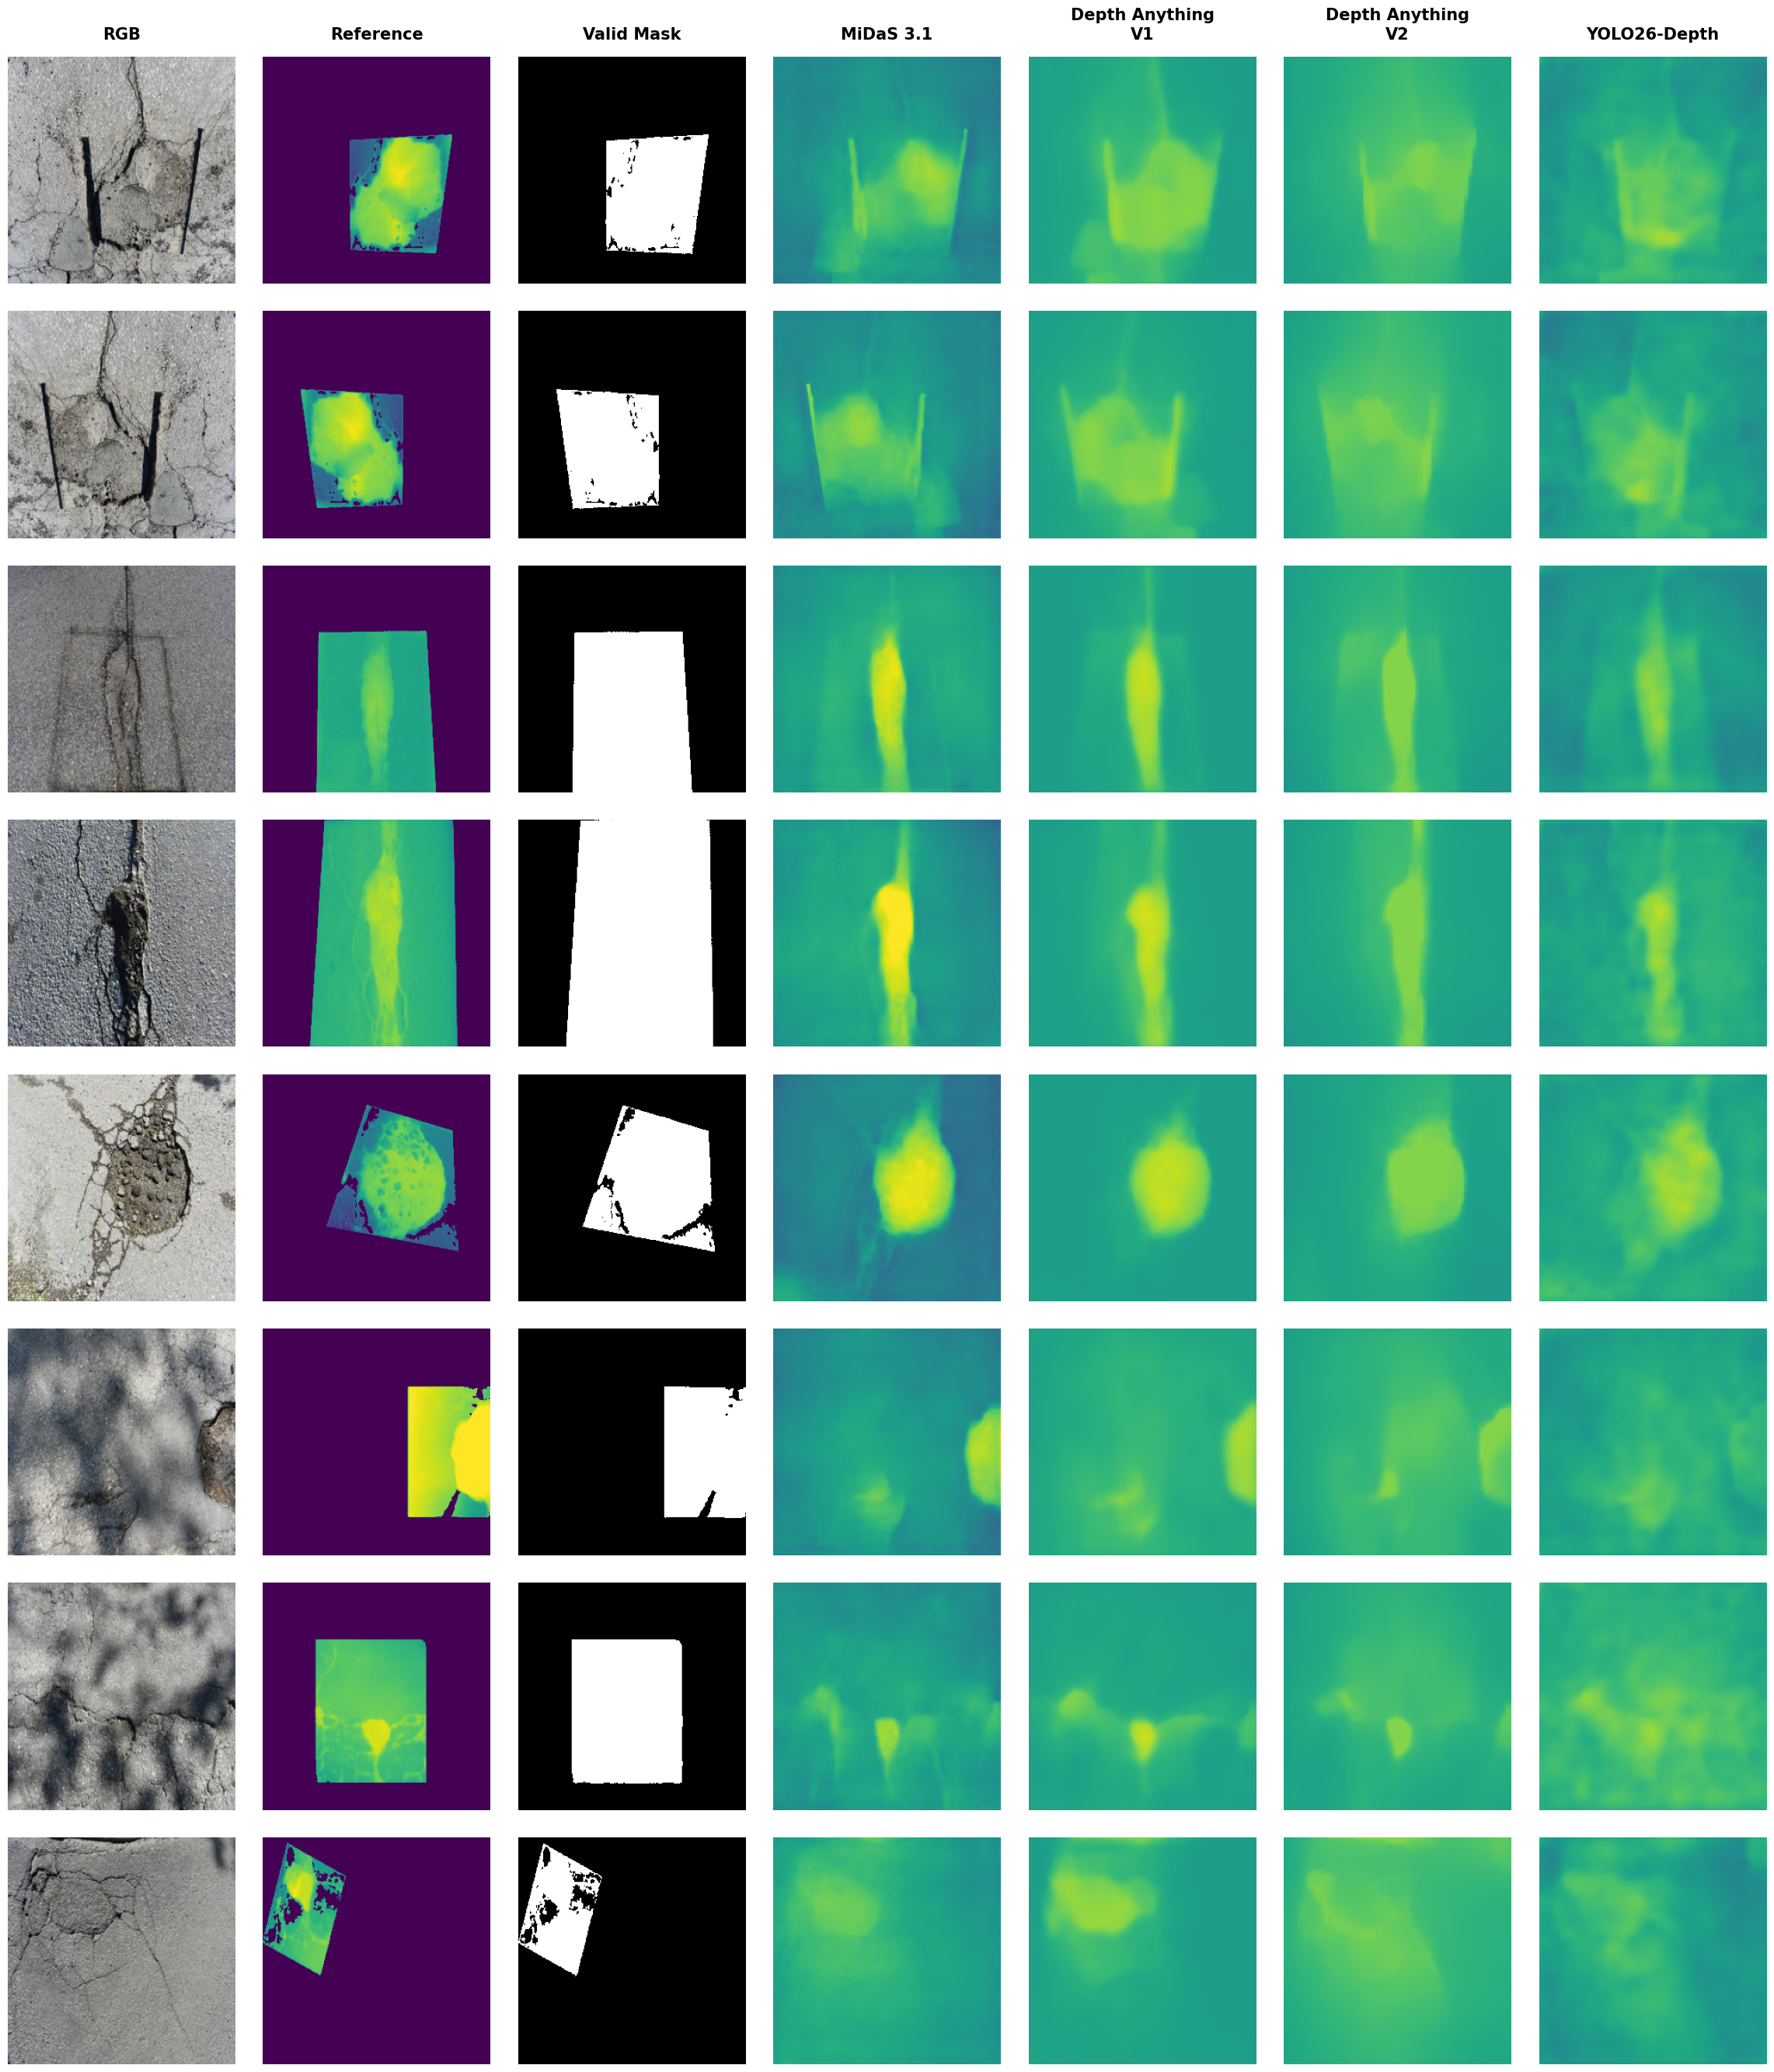

Saved: /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/visualizations/test_set_model_comparison_grid.png


In [13]:

# ============================================================
# QUALITATIVE COMPARISON — 7 COLUMN FORMAT
# Improved heading size, spacing and export resolution
# ============================================================

n_show = min(8, len(test_df))
indices = np.linspace(0, len(test_df) - 1, n_show, dtype=int)
selected_rows = test_df.iloc[indices]

model_prediction_dirs = {
    "MiDaS 3.1": PRED_ROOT / "MiDaS_3.1",
    "Depth Anything V1": PRED_ROOT / "Depth_Anything_V1",
    "Depth Anything V2": PRED_ROOT / "Depth_Anything_V2",
    "YOLO26-Depth": PRED_ROOT / "YOLO26_Depth",
}

plt.close("all")

fig, axes = plt.subplots(
    n_show, 7,
    figsize=(25, 3.4 * n_show),
    squeeze=False
)

titles = [
    "RGB",
    "Reference",
    "Valid Mask",
    "MiDaS 3.1",
    "Depth Anything\nV1",
    "Depth Anything\nV2",
    "YOLO26-Depth"
]

for r_i, (_, row) in enumerate(selected_rows.iterrows()):

    filename = str(row[NAME_COL])
    rgb, target, valid = reference_cache[filename]

    rgb_display = cv2.resize(
        np.asarray(rgb),
        (TARGET_SIZE, TARGET_SIZE),
        interpolation=cv2.INTER_AREA
    )

    axes[r_i, 0].imshow(rgb_display)
    axes[r_i, 1].imshow(target, cmap="viridis", vmin=0, vmax=1)
    axes[r_i, 2].imshow(valid, cmap="gray", vmin=0, vmax=1)

    for c_i, model_name in enumerate(model_order, start=3):

        model_dir = model_prediction_dirs[model_name]
        pred_file = model_dir / f"{Path(filename).stem}.npy"

        pred = np.load(pred_file)

        axes[r_i, c_i].imshow(
            pred,
            cmap="viridis",
            vmin=0,
            vmax=1
        )

    for c_i in range(7):
        axes[r_i, c_i].axis("off")

        if r_i == 0:
            axes[r_i, c_i].set_title(
                titles[c_i],
                fontsize=15,
                fontweight="bold",
                pad=16,
                linespacing=1.3
            )

    axes[r_i, 0].set_ylabel(
        Path(filename).stem[:28],
        fontsize=10,
        fontweight="medium",
        rotation=0,
        labelpad=48,
        va="center"
    )

fig.subplots_adjust(
    left=0.08,
    right=0.99,
    top=0.97,
    bottom=0.02,
    wspace=0.08,
    hspace=0.12
)

visual_path = VIS_ROOT / "test_set_model_comparison_grid.png"

plt.savefig(
    visual_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Saved:", visual_path)


## 10. Plot the results

These figures make it easier to compare the models:
- Error on individual test images
- Overall MAE and RMSE
- Approximate prediction time and model size


<Figure size 1000x500 with 0 Axes>

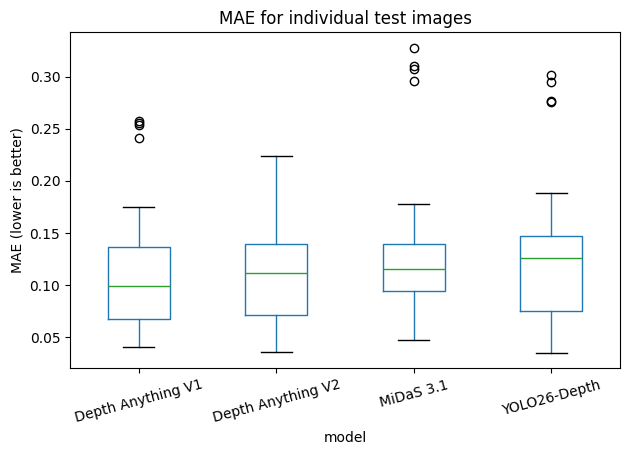

Saved: /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/visualizations/per_image_MAE_boxplot.png


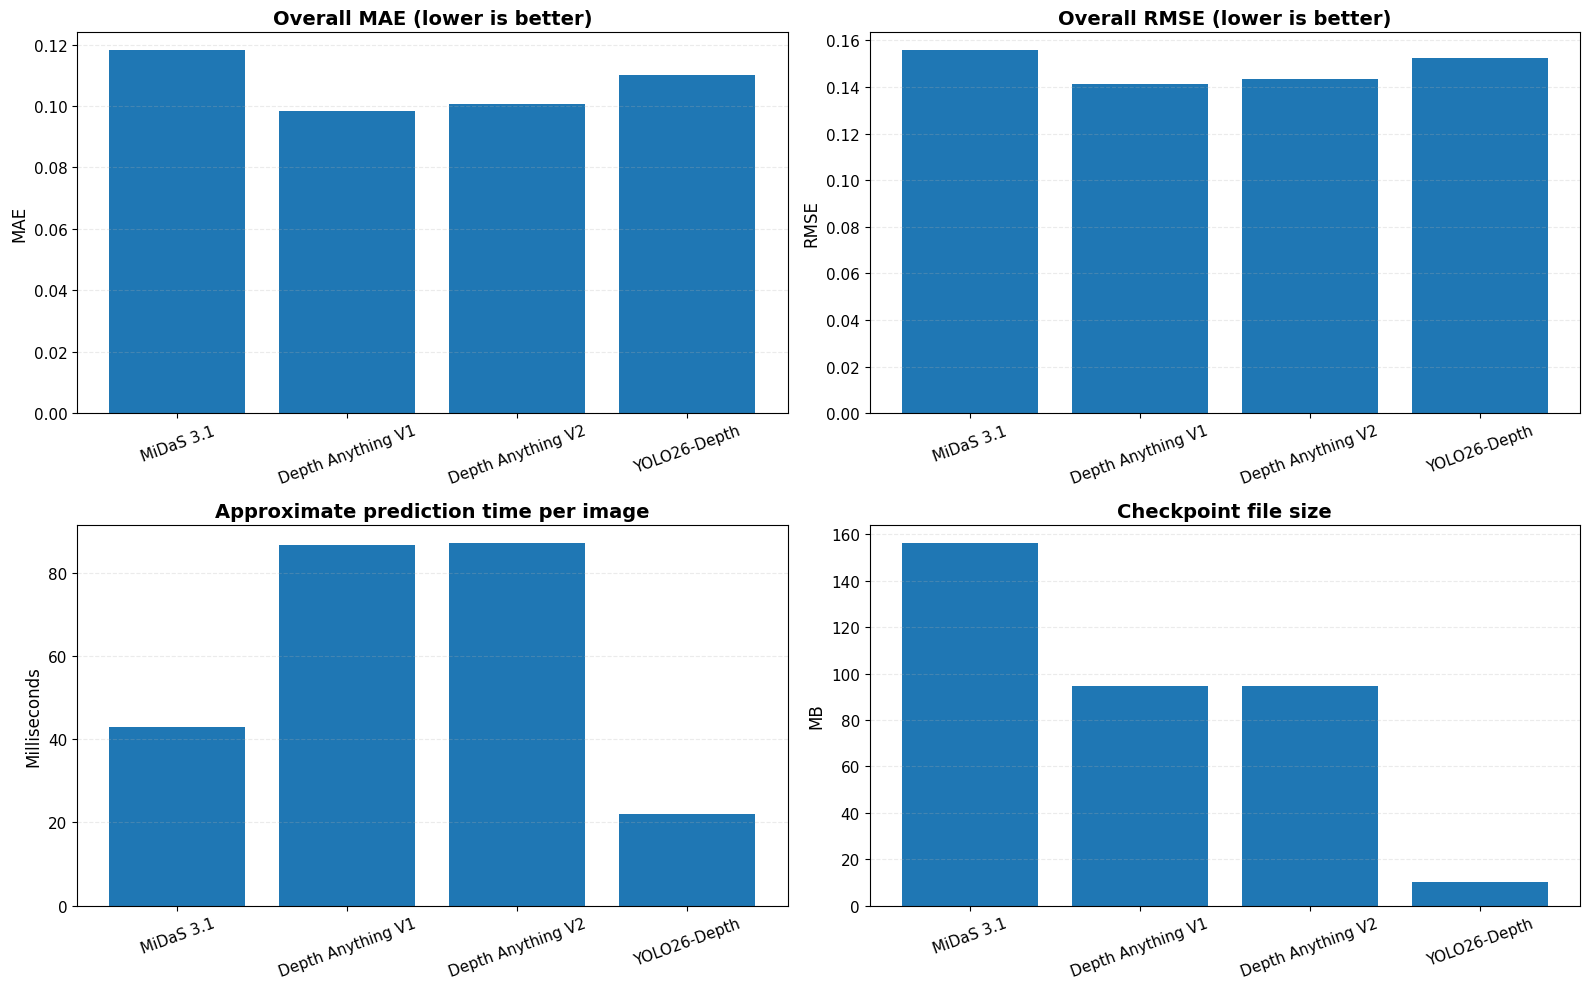

Saved: /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/visualizations/accuracy_speed_size_comparison.png


In [14]:
# 1) Compare the error on individual test images.
plot_data = []
for model_name, frame in all_per_image.items():
    for value in frame["MAE"].values:
        plot_data.append({"model": model_name, "MAE": float(value)})

plot_df = pd.DataFrame(plot_data)

plt.figure(figsize=(10, 5))
plot_df.boxplot(column="MAE", by="model", grid=False, rot=15)
plt.suptitle("")
plt.title("MAE for individual test images")
plt.ylabel("MAE (lower is better)")
plt.tight_layout()
box_path = VIS_ROOT / "per_image_MAE_boxplot.png"
plt.savefig(box_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", box_path)

# 2) Compare overall prediction errors and model speed/size.
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].bar(summary_df["model"], summary_df["pixel_weighted_MAE"])
axes[0, 0].set_title("Overall MAE (lower is better)")
axes[0, 0].set_ylabel("MAE")

axes[0, 1].bar(summary_df["model"], summary_df["pixel_weighted_RMSE"])
axes[0, 1].set_title("Overall RMSE (lower is better)")
axes[0, 1].set_ylabel("RMSE")

axes[1, 0].bar(summary_df["model"], summary_df["mean_inference_ms_per_image"])
axes[1, 0].set_title("Approximate prediction time per image")
axes[1, 0].set_ylabel("Milliseconds")

axes[1, 1].bar(summary_df["model"], summary_df["checkpoint_size_MB"])
axes[1, 1].set_title("Checkpoint file size")
axes[1, 1].set_ylabel("MB")

for ax in axes.flat:

    ax.tick_params(
        axis="both",
        labelsize=11
    )

    ax.tick_params(
        axis="x",
        rotation=20
    )

    ax.title.set_fontsize(14)
    ax.title.set_fontweight("bold")

    ax.yaxis.label.set_size(12)

    ax.grid(
        axis="y",
        alpha=0.25,
        linestyle="--"
    )

plt.tight_layout()
summary_plot_path = VIS_ROOT / "accuracy_speed_size_comparison.png"
plt.savefig(
    summary_plot_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()
print("Saved:", summary_plot_path)


## 11. Save notes for the report

The notebook writes a short record of the evaluation method and the important limits of the target data.


In [15]:
notes = f'''
POTHOLE-440 FOUR-MODEL EVALUATION
================================

Evaluation date: {pd.Timestamp.now().isoformat(timespec="seconds")}
Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}
Test images evaluated: {len(test_df)}
Evaluation grid: {TARGET_SIZE} x {TARGET_SIZE}
YOLO inference image size: {YOLO_IMGSZ}

MODELS
------
1. MiDaS 3.1: Intel/dpt-swinv2-tiny-256
2. Depth Anything V1: LiheYoung/depth-anything-small-hf
3. Depth Anything V2: depth-anything/Depth-Anything-V2-Small-hf
4. YOLO26-Depth: fine-tuned YOLO26 nano depth checkpoint

EVALUATION PROTOCOL
-------------------
- All models evaluated on the same test split from training_manifest_corrected.csv.
- Test split membership is determined by the manifest split column, not filename prefixes.
- All predictions are resized to the same {TARGET_SIZE} x {TARGET_SIZE} grid.
- All models use the same globally normalized reference targets and corrected validity masks.
- Invalid pixels are excluded from MAE and RMSE.
- MiDaS, DA V1 and DA V2 use affine calibration parameters stored in their checkpoints.
- YOLO26 output is compared directly with the normalized target.
- No calibration or parameter fitting was performed using the test set.
- Inference latency is approximate: model-specific preprocessing and input resolutions differ.

METRICS
-------
Pixel-weighted MAE/RMSE pool valid pixels across the test set.
Image-wise mean/median MAE/RMSE give each image equal weight.
Parameter count and checkpoint size are reported separately.
Inference time is measured after one warm-up inference per model.

IMPORTANT TARGET LIMITATIONS
----------------------------
The prepared target is a globally normalized scanner-grayscale intensity proxy.
The training normalization limits were derived from the training split (p1=16, p99=173).
These targets are NOT verified metric depth and do not represent metres or centimetres.
The scanner-support validity masks are corrected heuristic masks, not independently
verified geometric ground-truth masks. Therefore, results describe agreement with
the prepared scanner-intensity target, not physical depth accuracy.

OUTPUTS
-------
Summary CSV: {summary_path}
Per-image metrics: {METRIC_ROOT / "all_models_per_image_metrics.csv"}
Prediction arrays and PNG previews: {PRED_ROOT}
Visualizations: {VIS_ROOT}

INTERPRETATION LIMITS
--------------------
- A lower MAE/RMSE means closer agreement with the prepared scanner target.
- This does not prove better real-world or metric depth accuracy.
- Timing should be treated as approximate, not a perfectly controlled speed ranking.
- Visual maps should be discussed alongside the numerical scores.
'''

notes_path = REPORT_ROOT / "experiment_notes.txt"
notes_path.write_text(notes.strip() + "\n", encoding="utf-8")

# Save a machine-readable run configuration as well.
run_config = {
    "manifest": str(MANIFEST_PATH),
    "preparation_root": str(PREP_DIR),
    "checkpoint_root": str(MODEL_ROOT),
    "target_size": TARGET_SIZE,
    "yolo_imgsz": YOLO_IMGSZ,
    "test_images": int(len(test_df)),
    "models": {k: str(v) for k, v in CHECKPOINTS.items()},
    "target_description": "globally normalized scanner-grayscale proxy; not metric depth",
}
with open(REPORT_ROOT / "evaluation_config.json", "w", encoding="utf-8") as f:
    json.dump(run_config, f, indent=2)

print("Created:")
for p in [
    summary_path,
    notes_path,
    METRIC_ROOT / "all_models_per_image_metrics.csv",
    visual_path,
    box_path,
    summary_plot_path,
]:
    print(" -", p, "| exists:", p.exists())

print("\nEvaluation complete.")

# Bundle the complete results folder for easy download from Kaggle.
zip_path = Path(shutil.make_archive(str(OUTPUT_ROOT), "zip", root_dir=OUTPUT_ROOT))
print("Results ZIP:", zip_path, "| exists:", zip_path.exists(), "| size MB:", round(zip_path.stat().st_size / (1024**2), 2))

Created:
 - /kaggle/working/Pothole440_Model_Comparison/06_Reports/model_comparison.csv | exists: True
 - /kaggle/working/Pothole440_Model_Comparison/06_Reports/experiment_notes.txt | exists: True
 - /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/metrics/all_models_per_image_metrics.csv | exists: True
 - /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/visualizations/test_set_model_comparison_grid.png | exists: True
 - /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/visualizations/per_image_MAE_boxplot.png | exists: True
 - /kaggle/working/Pothole440_Model_Comparison/05_Evaluation/visualizations/accuracy_speed_size_comparison.png | exists: True

Evaluation complete.
Results ZIP: /kaggle/working/Pothole440_Model_Comparison.zip | exists: True | size MB: 56.23


## 12. Results folder and download

The notebook saves the results under:

```text
/kaggle/working/Pothole440_Model_Comparison/
├── 05_Evaluation/
│   ├── predictions/
│   ├── visualizations/
│   └── metrics/
└── 06_Reports/
    ├── model_comparison.csv
    ├── experiment_notes.txt
    └── evaluation_config.json
```

It also creates:

`/kaggle/working/Pothole440_Model_Comparison.zip`

In Kaggle, open the **Output** panel after the notebook finishes and download the ZIP. You can use the CSV tables and PNG figures in your report.
